# 16 — CartPole n-step DQN

m-step 보상과 γ^m Target Network Bootstrap으로 DQN을 학습한다. Buffer는 Return을 계산하지 않는다. 기본 FULL은 400 Episode, FAST는 8 Episode 연결 검증이다. 단일 Seed의 학습 성능은 수학적 단위 테스트와 별도로 해석한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation, MLPRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator, DiscreteQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator, NStepTargetGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule, TDLossUpdateRule
from modular_rl.component.buffer import ReplayBuffer, SequenceReplayBuffer
from modular_rl.data import Transition, Episode
from modular_rl.learner import (TabularQLearner, TabularSARSALearner, TabularTD0PredictionLearner,
    MCPredictionLearner, TabularMCControlLearner, OffPolicyMCPredictionLearner, OffPolicyMCControlLearner, DQNLearner)
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FULL', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('CartPole-v1', max_episode_steps=60 if FAST else 500)
eval_env = gym.make('CartPole-v1')
print(env.observation_space, env.action_space)
representation = MLPRepresentation(env.observation_space.shape[0], hidden_dims=(128,128))
estimator = DiscreteQEstimator(representation.output_dim, env.action_space.n)
selector = EpsilonGreedyActionSelector(1.)
model = Model(representation, estimator, selector)
target_model = deepcopy(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
target_generator = TD0TargetGenerator(GAMMA)
update_rule = TDLossUpdateRule(nn.SmoothL1Loss(reduction='none'))

n_step_target_generator = NStepTargetGenerator(GAMMA)
learner = DQNLearner(model, target_model, optimizer, target_generator, update_rule,
                     n_step_target_generator=n_step_target_generator)
buffer = SequenceReplayBuffer(10000, seed=SEED)
N = 3

learner.sync_target()
model.eval()
before = evaluate(eval_env, lambda observation: model.act(observation, deterministic=True).action.item(), episodes=3 if FAST else 20, seed=SEED+1000)
print('before mean return', np.mean(before['rewards']))
model.train()
BATCH_SIZE, WARMUP = (16,32) if FAST else (64,1000)
log, losses, epsilons, updates = history(), [], [], []
steps = gradient_updates = 0

Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) Discrete(2)


before mean return 9.2


### Sequence에서 실제 학습까지
`sample(B,length=3) → learner.learn(SequenceBatch)`가 직접 연결된다. Learner는 첫 observation/action의
Online Q를 gather하고 마지막 유효 next_observation의 현재 Target Q를 평가한다.
NStepTargetGenerator는 Mask로 실제 m을 구해 보상 합과 γ^m Bootstrap을 만들고 기존 optimize를 재사용한다.
열린 짧은 Tail은 후보가 아니며 terminated/truncated 경계에서만 길이 1/2 Tail을 확정한다.
자연 종료는 Bootstrap하지 않고 Time-limit은 실제 마지막 관측에서 Bootstrap한다.

episode 50 return 11.0 epsilon 0.9019 loss 2.112047 steps 1034 updates 35


episode 100 return 38.0 epsilon 0.8107 loss 0.746008 steps 1994 updates 995


episode 150 return 38.0 epsilon 0.6824 loss 3.025307 steps 3344 updates 2345


episode 200 return 260.0 epsilon 0.3388 loss 3.518848 steps 6961 updates 5962


episode 250 return 172.0 epsilon 0.05 loss 1.585715 steps 13300 updates 12301


episode 300 return 426.0 epsilon 0.05 loss 2.455306 steps 29693 updates 28694


episode 350 return 249.0 epsilon 0.05 loss 1.880556 steps 47233 updates 46234


episode 400 return 292.0 epsilon 0.05 loss 1.106251 steps 61342 updates 60343


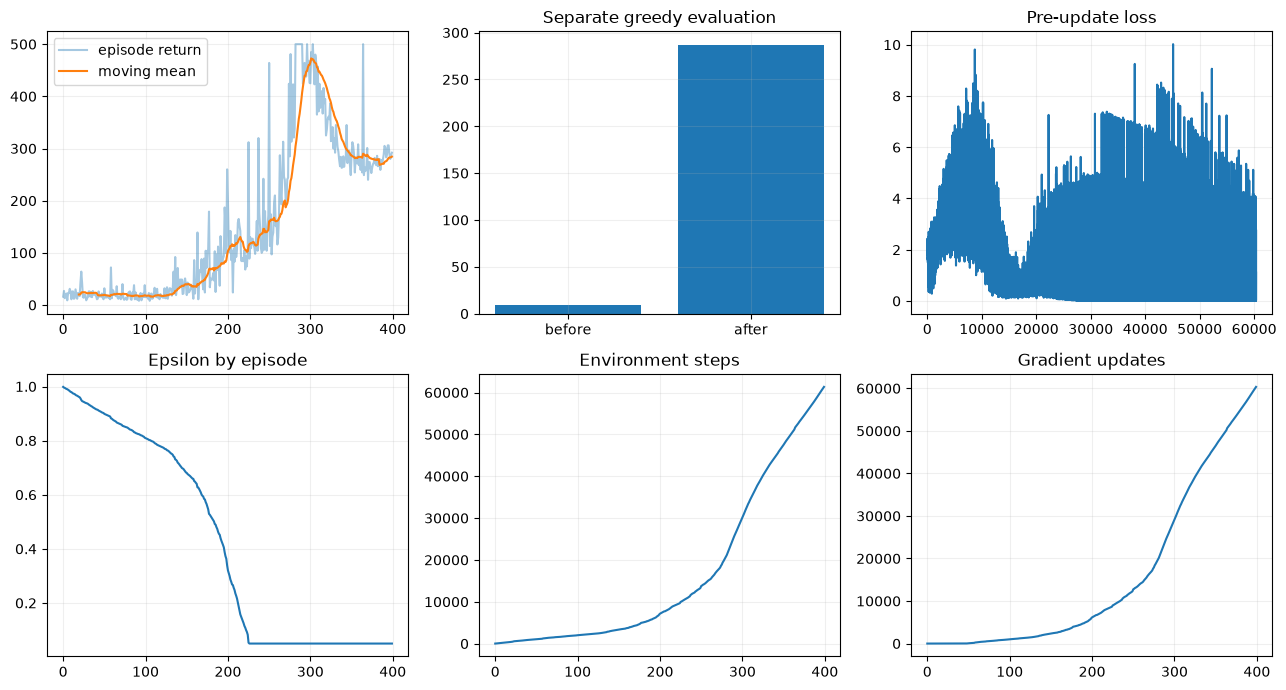

RESULT {"after": 287.0, "before": 9.2, "environment_steps": 61342, "episodes": 400, "gradient_updates": 60343, "last_loss": 1.1062506437301636}


In [3]:
for episode_index in range(8 if FAST else 400):
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    total, length = 0., 0
    while True:
        selector.epsilon = max(.05, 1.-.95*steps/(500 if FAST else 10000))
        selected = model.act(observation)
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약
        buffer.add(observation, selected.action, reward, next_observation, terminated, truncated)
        steps += 1
        if len(buffer) >= WARMUP and buffer.num_sequences(N) >= BATCH_SIZE:
            batch = buffer.sample(BATCH_SIZE, length=N)
            result = learner.learn(batch)
            losses.append(result.loss.item()); gradient_updates += 1
        if steps % 250 == 0: learner.sync_target()
        total += reward; length += 1; observation = next_observation
        if terminated or truncated: break
    record(log, total, length, terminated, truncated)
    epsilons.append(selector.epsilon); updates.append(gradient_updates)
    if (episode_index+1) % (4 if FAST else 50) == 0:
        print('episode',episode_index+1,'return',total,'epsilon',round(selector.epsilon,4),
              'loss',round(losses[-1],6) if losses else None,'steps',steps,'updates',gradient_updates)
model.eval()
after = evaluate(eval_env, lambda observation: model.act(observation, deterministic=True).action.item(), episodes=3 if FAST else 20, seed=SEED+1000)
summary = neural_report(log, losses, epsilons, updates, before, after)
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
Model/Optimizer/TargetGenerator/UpdateRule/Replay를 명시적으로 선택한다. 같은 learn 진입점이 SequenceBatch를 받아 n-step 수식을 Notebook에서 재구현하지 않는다. 혼합 Horizon과 Planning 1-step도 같은 Optimizer를 사용할 수 있다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.